Problem 1

In [44]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from tabulate import tabulate

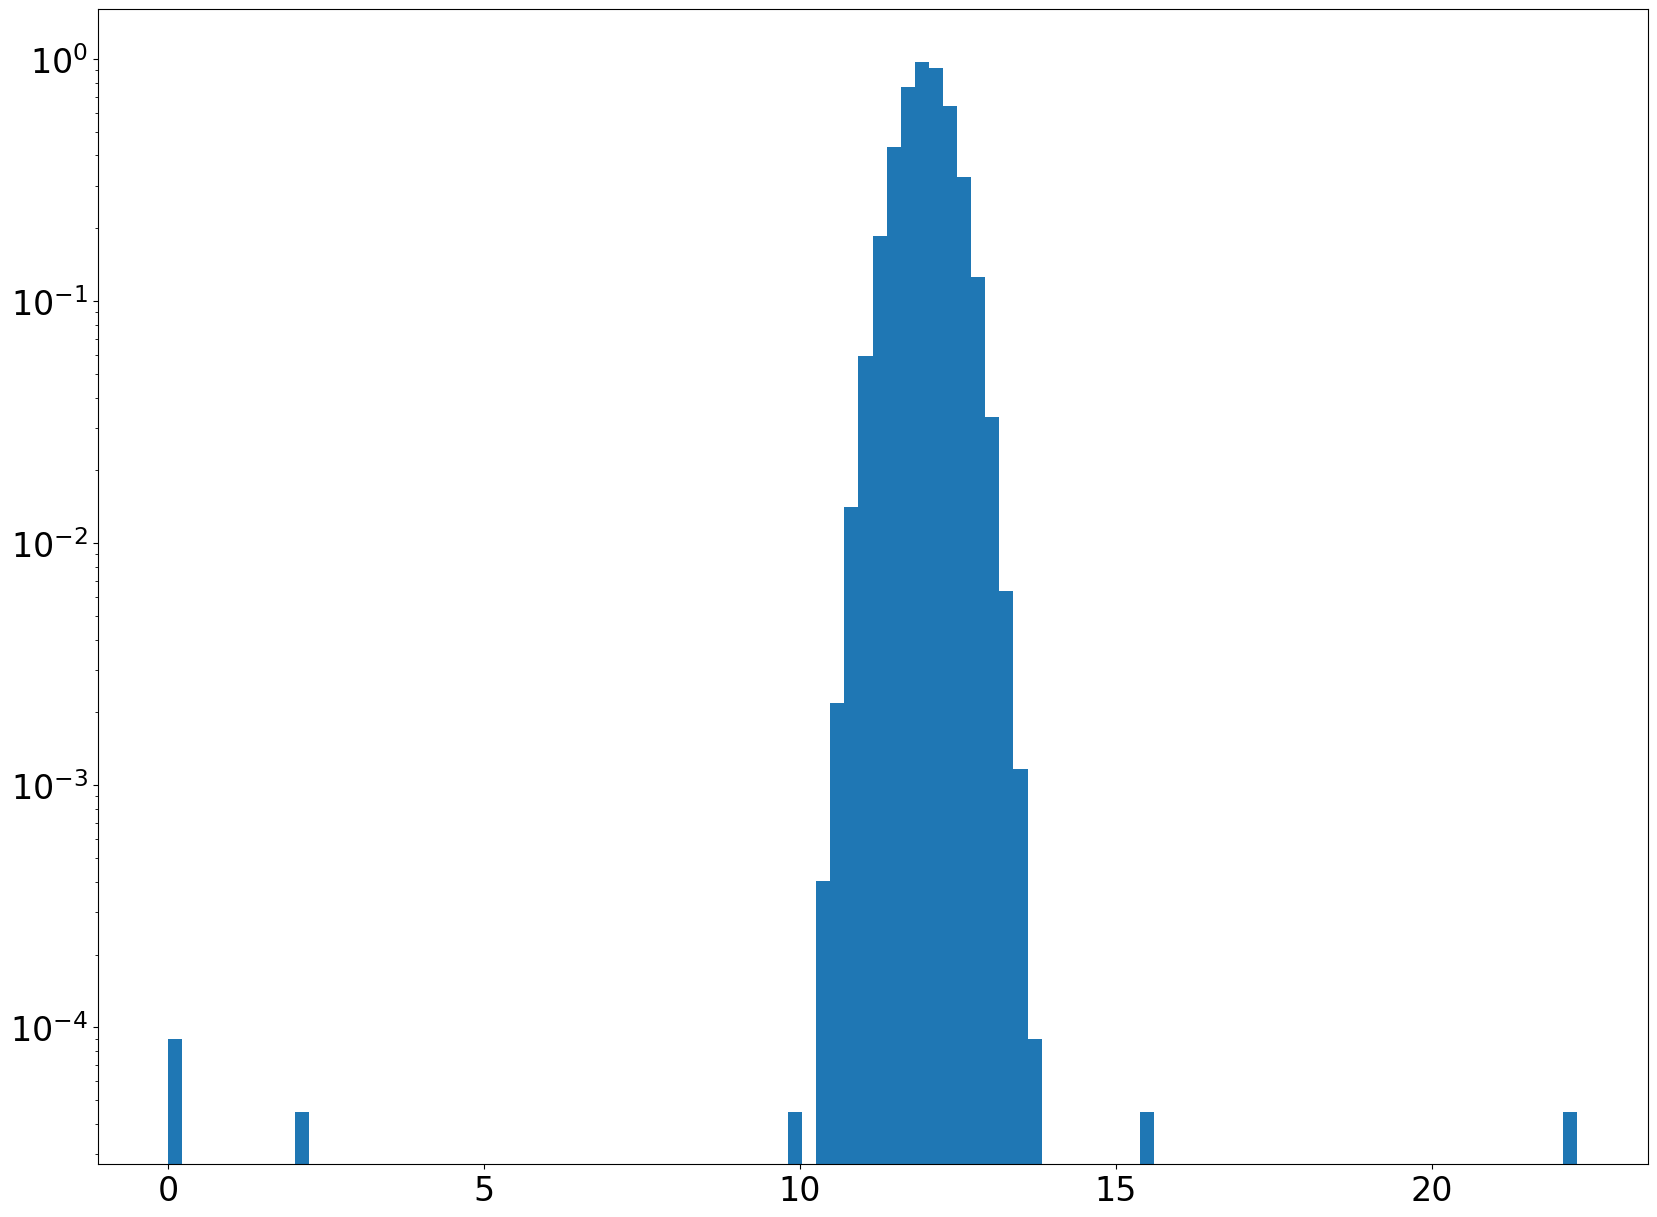

In [3]:
#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

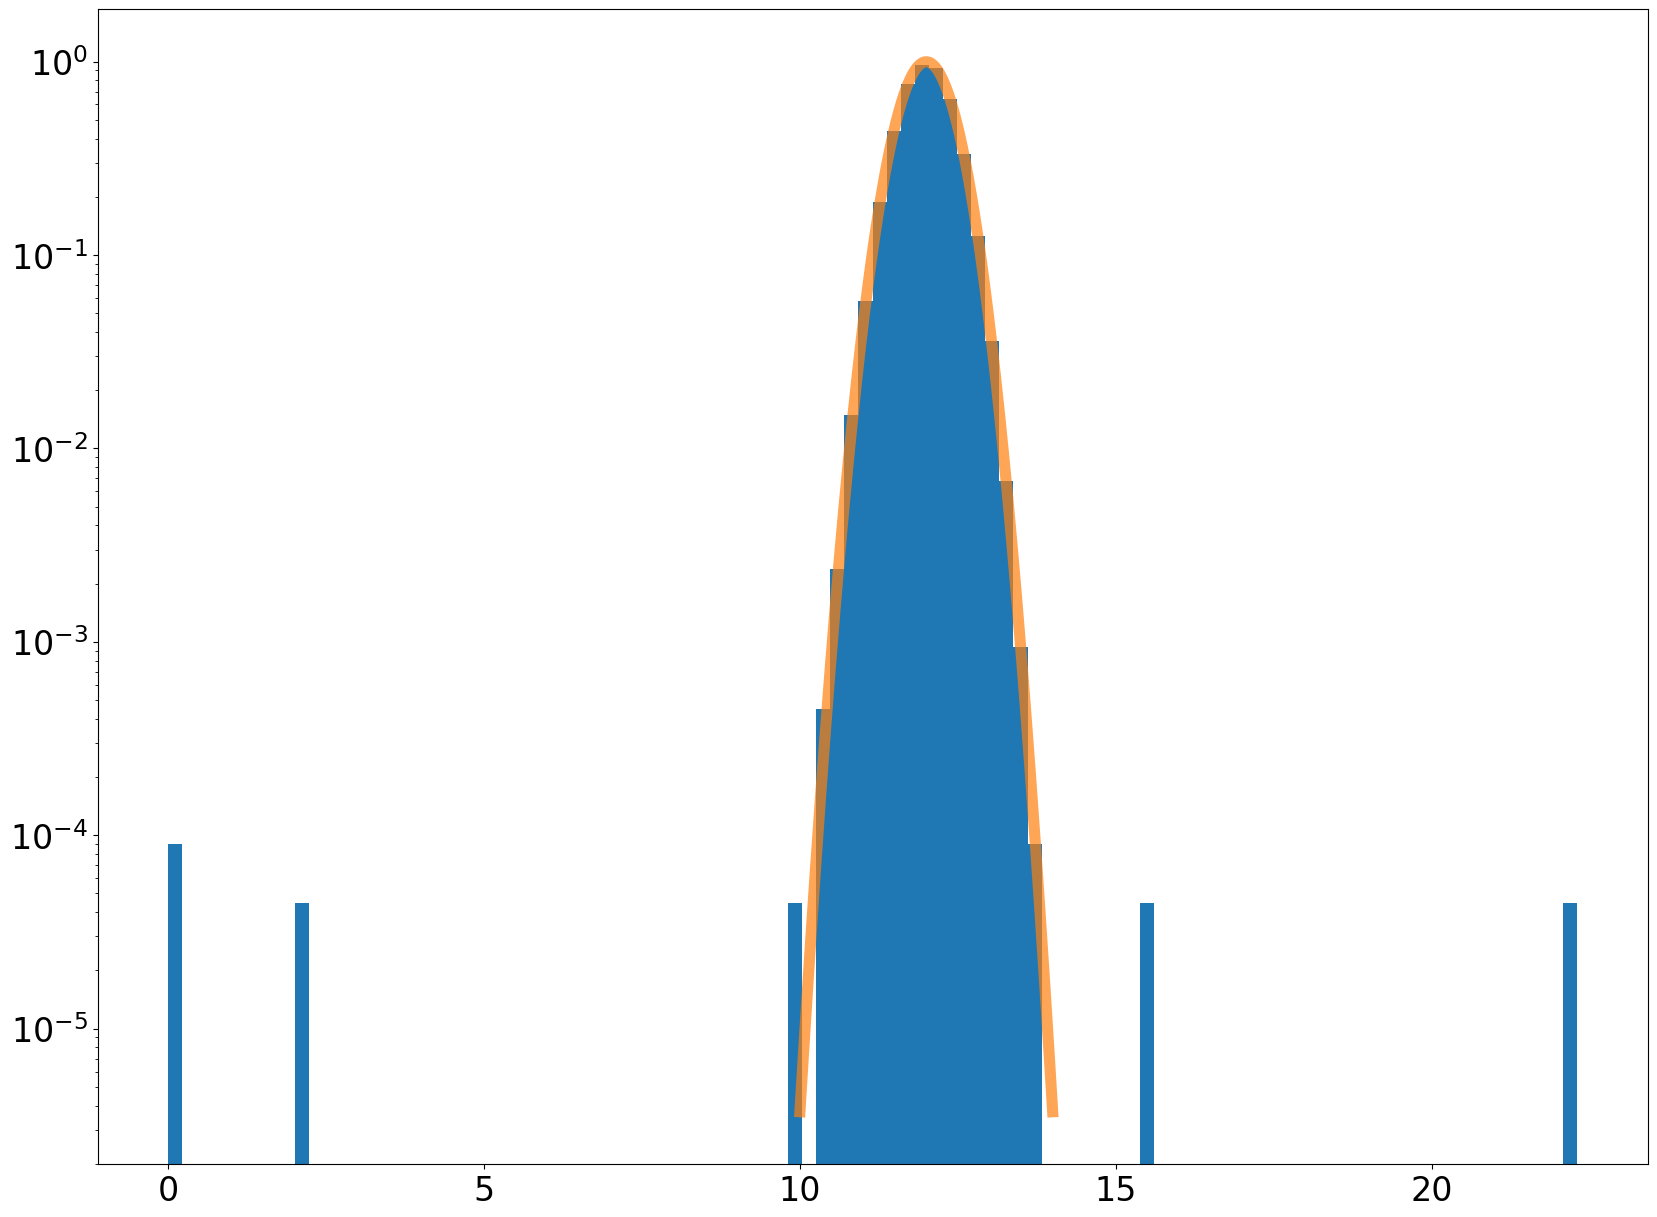

In [16]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
# plotting the normal probability distribution function against d to see how normal the distribution is
x = np.linspace(10.,14.,1000)
ax.plot(x,stats.norm.pdf(x,loc = 12., scale = 0.4),linewidth = 8,alpha = 0.7)
plt.show()

a)

The data appears mostly gaussian (except for outliers) since when plotted against a semi-log y graph, the 
main shape is upside down quadratic and since the normal PDF when plotted on the same graph as the distribution
matches the primary shape of the data.

The statistical question is: How many data points have a z-score greater than 4 or less than -4.
In math: z= [(data value) - mean] / standard deviation > |4|

In [39]:
mean, std = stats.norm.fit(d)

for x in d:
    z = (x-mean)/std
    if abs(z) > 4:
        print(x)

10.304113771921752
10.352211936830939
10.0
10.3
2.1
0.0
0.0
15.6
22.3


In [41]:
# finding how many were correctly read as z < |4|
print(len(d)-10)

99998


In [46]:
headers = [" ","True T", "Bad T"]
data = [
    ["My Test Good", 99998, 1],
    ["My Test Bad", 2, 7]
]

print(tabulate(data, headers=headers, tablefmt="grid"))

+--------------+----------+---------+
|              |   True T |   Bad T |
+==============+==========+=========+
| My Test Good |    99998 |       1 |
+--------------+----------+---------+
| My Test Bad  |        2 |       7 |
+--------------+----------+---------+


b)

The number of ommissions depends on my statistical threshold because if any "good" data is outside of my z-score limit, it will be removed.

With my statistical threshold, there were only 2 ommissions, but this is not a predictable quantity since there could be any number of false reading with a z-score below the absolute value of 4. In fact, it could be that every bad data point is read as good with this method. However, in this case, it works very well with only 2 out of 100008 data points being ommissions.

c)

The number of commissions depends on my statistical threshold because if any "bad" data is within my z-score limit, then it will be read as "good" data by my threshold. 
For example, in my case the bad temperature reading of 12.7 has a z-score that is less than the absolute value of 4, so it was counted as a good temperature reading even when it wasn't. 
In my case, there was only 1 commission, however, it would be pretty unavoidable without knowing the incorrect data beforehand to remove this 12.7 data point since it is so close to what many good readings are.


Problem 2

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_221/2121784878.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
/tmp/ipykernel_221/2121784878.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel("$\Delta$x arcseconds", fontsize = 18)


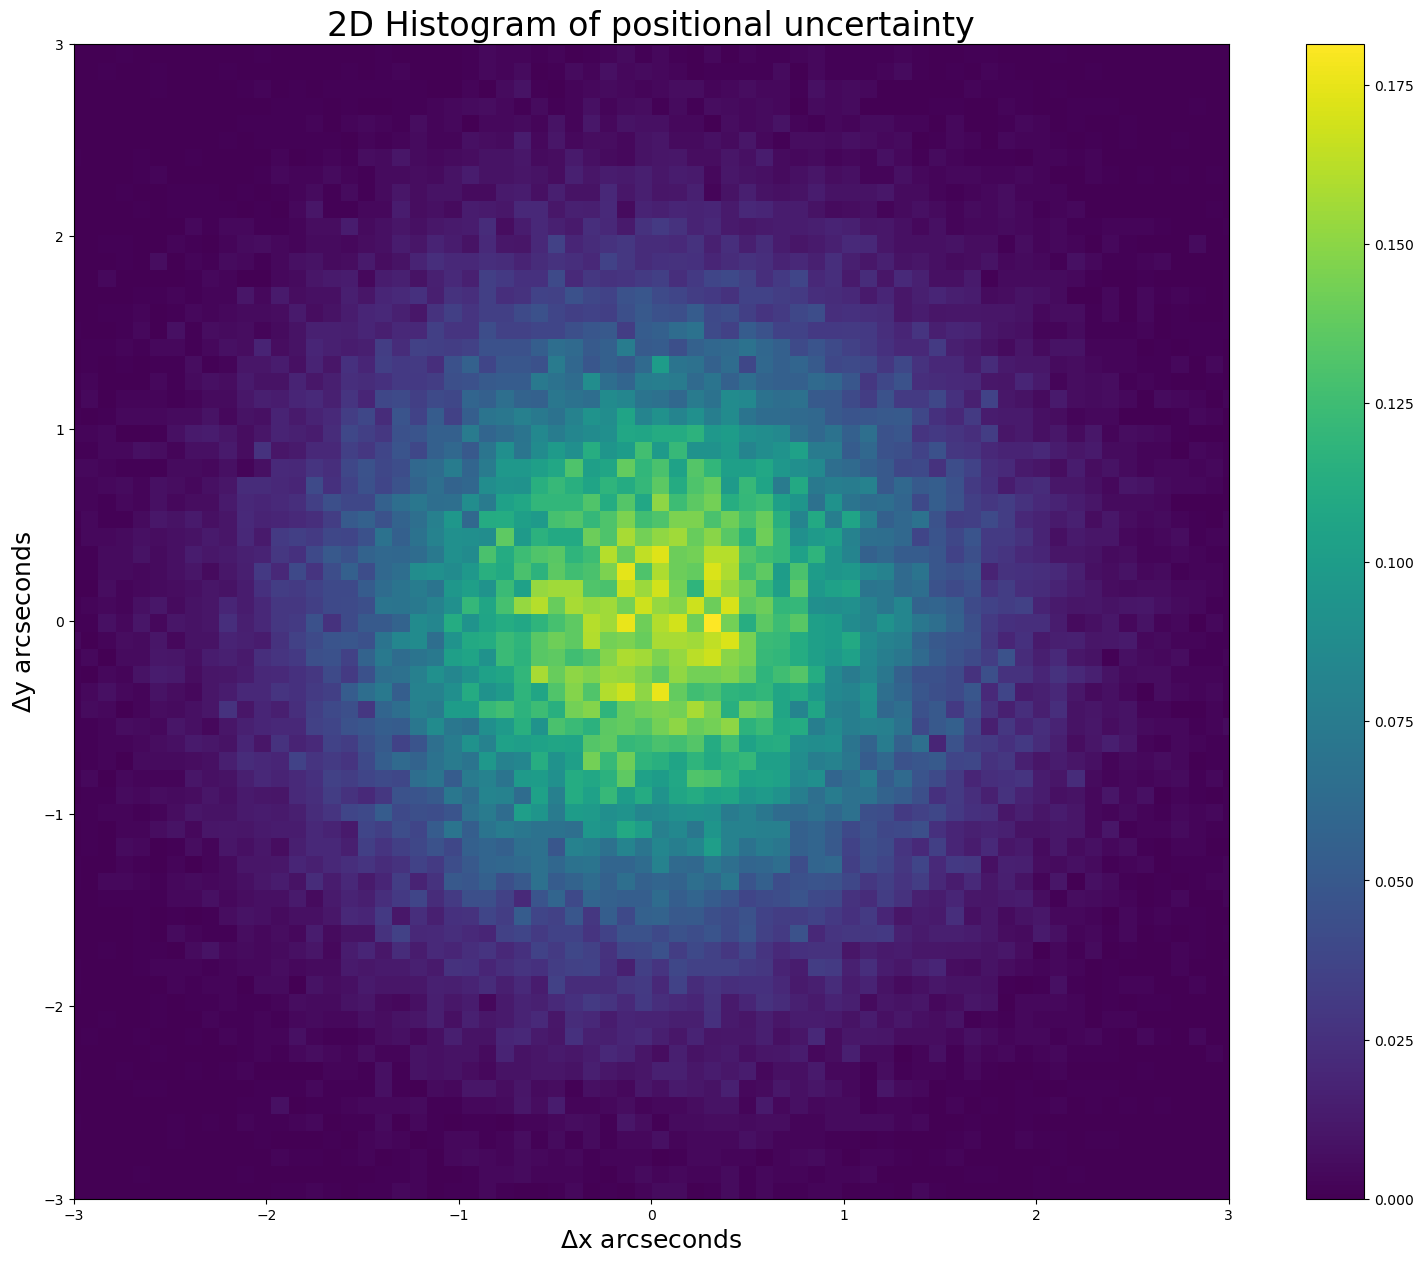

In [47]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
plt.xlabel("$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

Statistical question: What distance in arcseconds corresponds to a 5 sigma reading away from the mean of the 2d positional uncertainty distribution?

In math: $S^{-1}=\sigma\sqrt{-2\ln{p}}$, where p = 2.87e-7 (corresponding to 5 sigma) and sigma = 1

In [50]:
print(a)

[[-0.44147876  1.85842263  1.63707579 ... -1.79191803  1.02194623
   0.51490842]
 [-1.19163216 -0.40858279  0.11013028 ...  0.090376   -2.63980835
  -0.22290025]]


In [63]:
# Since both have a mean of 0 and standard deviation of 1, we can use the Rayleigh distribution.

R = np.sqrt((a[0,:])**2 + (a[1,:])**2)
print(R)

[1.2707835  1.90280703 1.64077598 ... 1.79419566 2.83071762 0.56108395]


In [70]:
# A five sigma reading corresponds to a probability of 2.87e-7
p = 2.87e-7
# Inverse survival function to get 'five sigma' score
fivesigma = stats.rayleigh.isf(p)
print(fivesigma)


5.488858464414398


Problem 3